In [1]:
import numpy as np
import matplotlib.pylab as plt
%matplotlib inline
import healpy as hp
from rubin_scheduler.scheduler.utils import CurrentAreaMap, Footprint, make_rolling_footprints
from rubin_scheduler.utils import DEFAULT_NSIDE

In [2]:
class FootprintCount(Footprint):

    def __init__(self, mjd_start,
        sun_ra_start=0,
        nside=DEFAULT_NSIDE,
        bands=["u", "g", "r", "i", "z", "y"],
        filters=None,
        period=365.25,
        step_func=None,
        n_per_year=3.,):
            super().__init__(mjd_start, sun_ra_start=sun_ra_start, nside=nside, bands=bands, period=period,step_func=step_func)
            self.n_per_year = n_per_year
    
    def _update_mjd(self, mjd, norm=False):
        if mjd != self.mjd_current:
            self.mjd_current = mjd
            t_elapsed = mjd - self.mjd_start

            norm_coverage = self.step_func(t_elapsed, self.phase)
            norm_coverage -= self.zero
            self.current_footprints = self.footprints * norm_coverage
            self.current_footprints *= self.n_per_year

    

In [3]:
sag = CurrentAreaMap()
sky_maps, labels = sag.return_maps()


In [4]:
# Instatiate our Footprint object, and set each band
mjd_start = 60218

fp = FootprintCount(mjd_start, 0)
mjds = np.linspace(1,365*2, 8) + mjd_start

for bandname in 'ugrizy':
    fp.set_footprint(bandname, sky_maps[bandname])


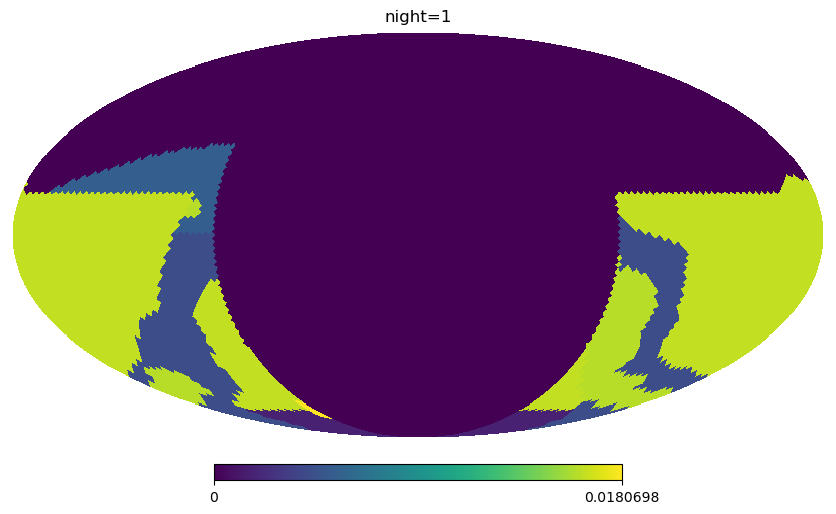

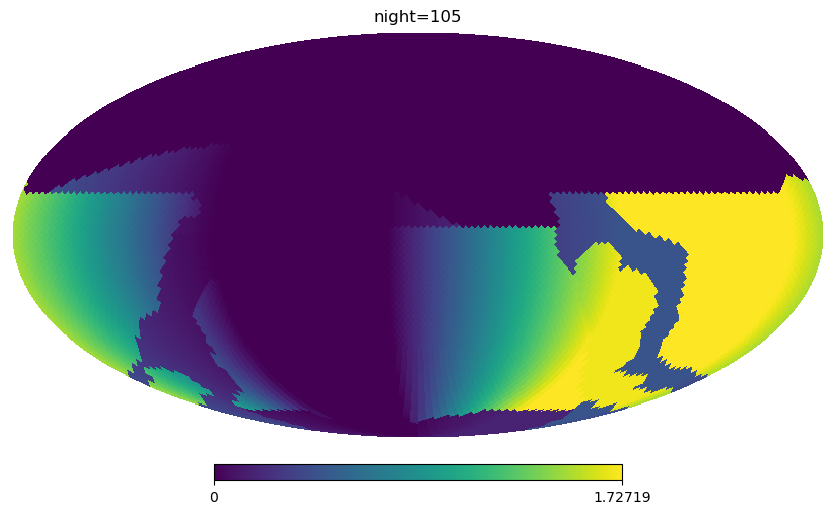

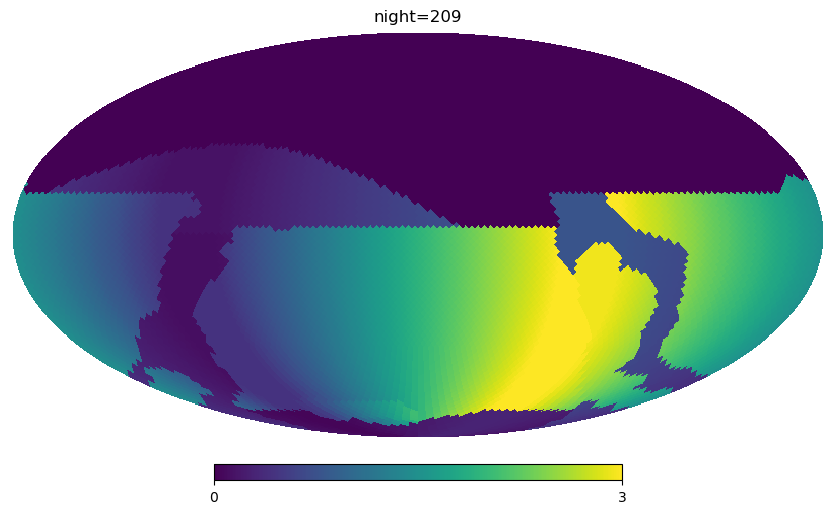

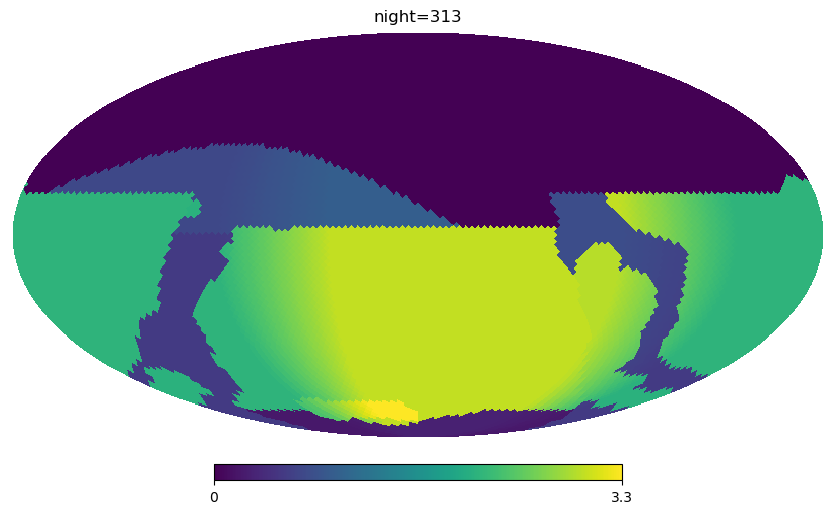

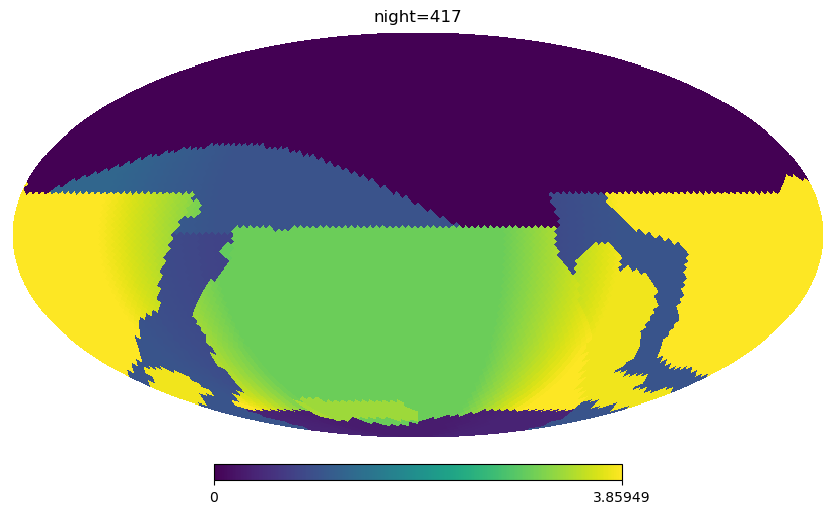

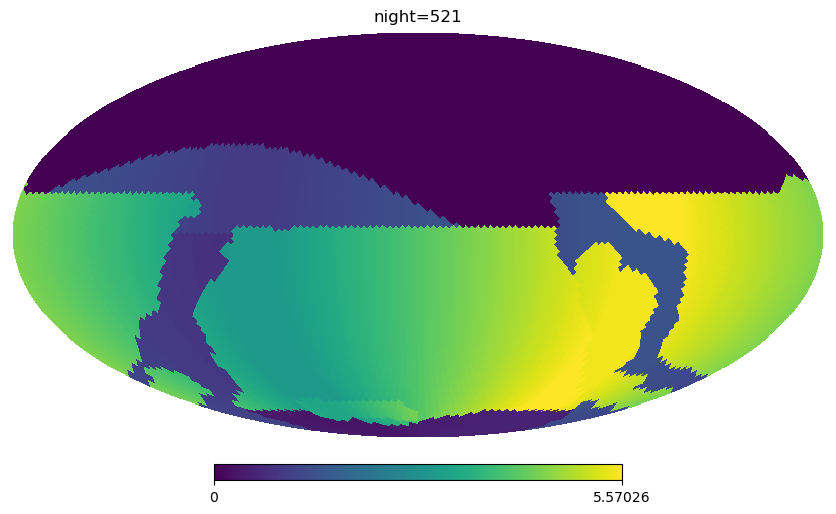

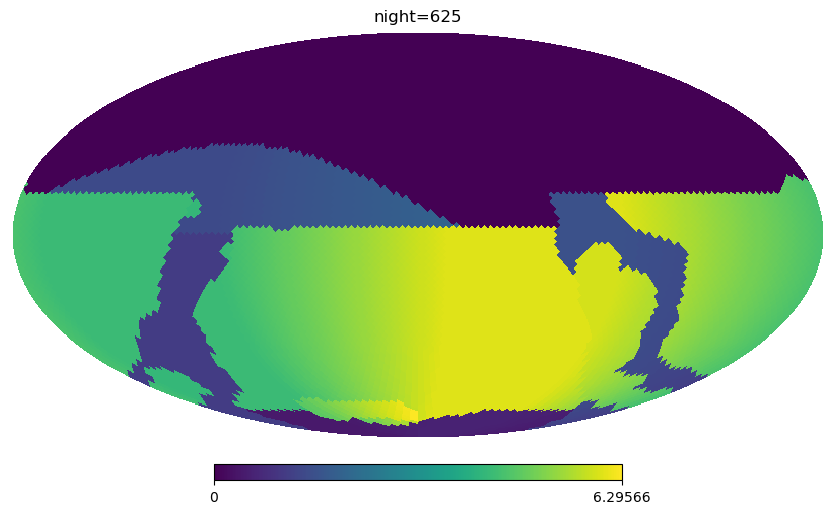

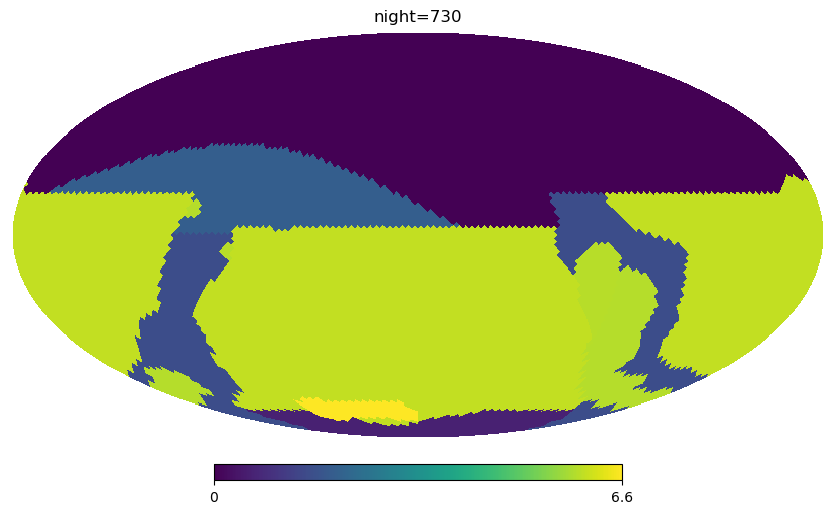

In [5]:
for mjd in mjds:
    fp_at_mjd = fp(mjd)
    hp.mollview(fp_at_mjd['r'], title='night=%i' % (mjd-mjd_start))

